In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LeakyReLU

In [2]:
(x_train, _), (_, _) = mnist.load_data()
x_train = x_train.reshape(-1, 784) / 127.5 - 1

In [3]:
G = Sequential([
    Dense(128, input_dim=100),
    LeakyReLU(negative_slope=0.2),
    Dense(784, activation='tanh')
])

f:\BTech\DL\Lab\.venv\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [4]:
D = Sequential([
    Dense(128, input_dim=784),
    LeakyReLU(negative_slope=0.2),
    Dense(1, activation='sigmoid')
])


In [5]:
D.compile(optimizer='adam', loss='binary_crossentropy')
D.trainable = False

In [6]:
GAN = Sequential([G, D])
GAN.compile(optimizer='adam', loss='binary_crossentropy')

In [7]:
for epoch in range(1000):
    idx = np.random.randint(0, len(x_train), 32)
    real = x_train[idx]

    noise = np.random.normal(0, 1, (32, 100))
    fake = G.predict(noise, verbose=0)

    D.trainable = True
    D.train_on_batch(real, np.ones((32, 1)))
    D.train_on_batch(fake, np.zeros((32, 1)))

    D.trainable = False
    noise = np.random.normal(0, 1, (32, 100))
    GAN.train_on_batch(noise, np.ones((32, 1)))

In [8]:
noise = np.random.normal(0, 1, (10, 100))
images = G.predict(noise, verbose=0)

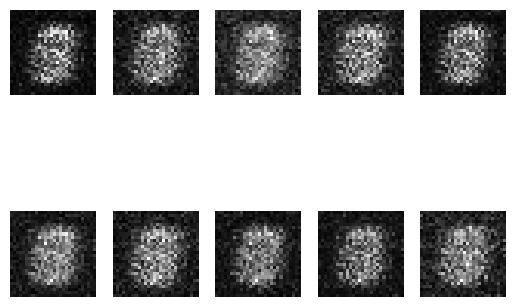

In [9]:
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].reshape(28, 28), cmap='gray')
    plt.axis('off')
plt.show()